In [1]:
print('hello world')

hello world


In [2]:
pip install pandas numpy matplotlib scipy jupyter ipykernel


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

In [4]:
df = pd.read_csv("data/day.csv")

df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [5]:
print('Shape of dataframe: ', df.shape)
df.info()

Shape of dataframe:  (731, 16)
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [6]:
missing = df.isna().sum()
print(missing)

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [7]:
print('Duplicated days: ', df['dteday'].duplicated().sum())

print('Minimum rentals: ', df['cnt'].min())
print('Maximum rentals: ', df['cnt'].max())

print('Negative rentals: ', (df['cnt'] < 0).sum())

print("Rental count errors: ", (df['casual']+ df['registered'] != df['cnt']).sum())

Duplicated days:  0
Minimum rentals:  22
Maximum rentals:  8714
Negative rentals:  0
Rental count errors:  0


In [8]:
df["dteday"] = pd.to_datetime(df["dteday"])

print("First date:", df["dteday"].min())
print("Last date:", df["dteday"].max())

print("Unique dates:", df["dteday"].nunique())

First date: 2011-01-01 00:00:00
Last date: 2012-12-31 00:00:00
Unique dates: 731


In [9]:
df['weather_group'] = np.where(
    df['weathersit'] == 1,
    "Clear",
    "Non-Clear"
)

df['weather_group'].value_counts()

weather_group
Clear        463
Non-Clear    268
Name: count, dtype: int64

<Figure size 800x500 with 0 Axes>

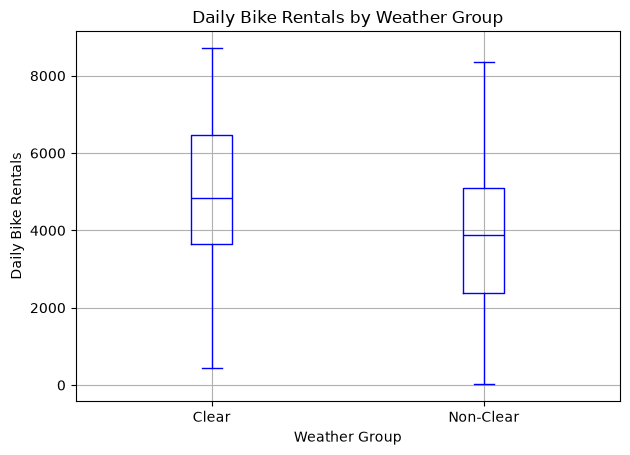

In [10]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="cnt",
    by="weather_group",
    grid=True, color = 'blue'
)

plt.title("Daily Bike Rentals by Weather Group")
plt.suptitle("")
plt.xlabel("Weather Group")
plt.ylabel("Daily Bike Rentals")

plt.tight_layout()
plt.show()

In [11]:
df.groupby('weather_group')['cnt'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
weather_group,,,,,,,,
Clear,463.0,4876.79,1879.48,431.0,3636.5,4844.0,6458.5,8714.0
Non-Clear,268.0,3860.92,1868.69,22.0,2374.0,3883.0,5103.0,8362.0


In [12]:
clear = df[df["weather_group"] == "Clear"]["cnt"]
non_clear = df[df["weather_group"] == "Non-Clear"]["cnt"]

clear_mean = clear.mean()
non_clear_mean = non_clear.mean()

difference = clear_mean - non_clear_mean

relative_difference = (difference / non_clear_mean) * 100

print("Clear day mean:", round(clear_mean, 2))
print("Non-clear day mean:", round(non_clear_mean, 2))

print("Absolute difference:", round(difference, 2))
print("Relative difference:", round(relative_difference, 2), "%")

Clear day mean: 4876.79
Non-clear day mean: 3860.92
Absolute difference: 1015.86
Relative difference: 26.31 %


In [13]:
n1 = len(clear)
n2 = len(non_clear)

v1 = clear.var()
v2 = non_clear.var()

se = np.sqrt(v1/n1 + v2/n2)

degrees_freedom = (
    (v1 / n1 + v2 / n2) ** 2
    /
    (
        (v1 / n1) ** 2 / (n1 - 1)
        +
        (v2 / n2) ** 2 / (n2 - 1)
    )
)

margin = stats.t.ppf(0.975, degrees_freedom) * se

ci_lower = difference - margin
ci_upper = difference + margin

print("Difference:", round(difference, 2))
print("95% CI:", round(ci_lower, 2),
      "to", round(ci_upper, 2))

Difference: 1015.86
95% CI: 733.54 to 1298.19


In [14]:
threshold = 0.10 * non_clear_mean

print("10% capacity threshold:", round(threshold, 2))

print("Estimated difference:", round(difference, 2))
print("Lower CI bound:", round(ci_lower, 2))

10% capacity threshold: 386.09
Estimated difference: 1015.86
Lower CI bound: 733.54


<Figure size 800x500 with 0 Axes>

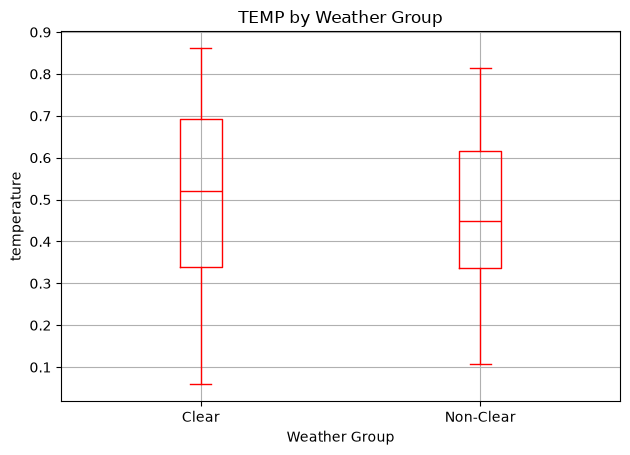

In [15]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="temp",
    by="weather_group",
    grid=True, color = 'red'
)

plt.title("TEMP by Weather Group")
plt.suptitle("")
plt.xlabel("Weather Group")
plt.ylabel("temperature")

plt.tight_layout()
plt.show()

In [16]:
temperature_summary = df.groupby('weather_group')['temp'].describe()

print(temperature_summary.round(2))

               count  mean   std   min   25%   50%   75%   max
weather_group                                                 
Clear          463.0  0.51  0.19  0.06  0.34  0.52  0.69  0.86
Non-Clear      268.0  0.47  0.16  0.11  0.34  0.45  0.62  0.82


Temperature-rental correlation: 0.627


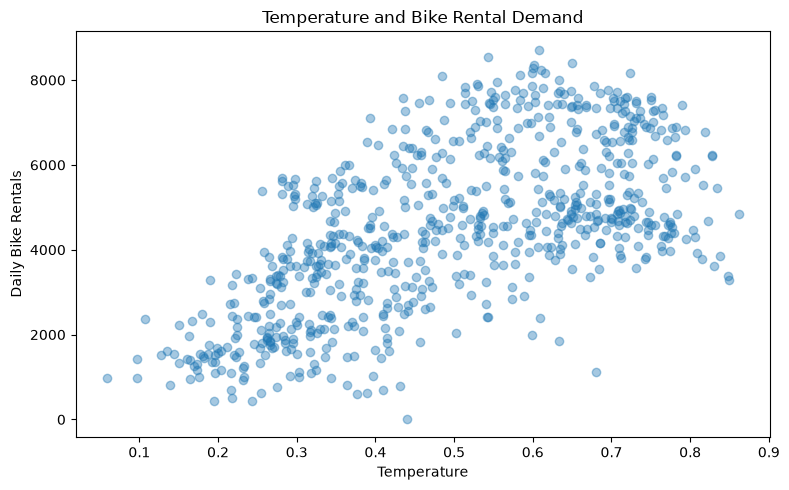

In [17]:
correlation = df['temp'].corr(df['cnt'])

print("Temperature-rental correlation:",
      round(correlation, 3))

plt.figure(figsize=(8, 5))

plt.scatter(
    df["temp"],
    df["cnt"],
    alpha=0.4
)

plt.xlabel("Temperature")
plt.ylabel("Daily Bike Rentals")
plt.title("Temperature and Bike Rental Demand")

plt.tight_layout()
plt.show()

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   dteday         731 non-null    datetime64[us]
 2   season         731 non-null    int64         
 3   yr             731 non-null    int64         
 4   mnth           731 non-null    int64         
 5   holiday        731 non-null    int64         
 6   weekday        731 non-null    int64         
 7   workingday     731 non-null    int64         
 8   weathersit     731 non-null    int64         
 9   temp           731 non-null    float64       
 10  atemp          731 non-null    float64       
 11  hum            731 non-null    float64       
 12  windspeed      731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non-null    int

In [19]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt', 'weather_group'],
      dtype='str')

In [20]:
features = ['temp', 'atemp', 'holiday', 'yr', 'mnth', 'hum', 'windspeed', 'season', 'weekday', 'workingday', 'weathersit']
correlation_new = df[features].corrwith(df['cnt']).sort_values()
correlation_new

weathersit   -0.297391
windspeed    -0.234545
hum          -0.100659
holiday      -0.068348
workingday    0.061156
weekday       0.067443
mnth          0.279977
season        0.406100
yr            0.566710
temp          0.627494
atemp         0.631066
dtype: float64

In [21]:
correlation_season = df['temp'].corr(df['season'])
correlation_season

np.float64(0.33431485639909503)

In [22]:
df['temp_band'] = pd.qcut(
    df['temp'],
    q = 4,
    labels = ['Q1','Q2','Q3','Q4']
)

print(df['temp_band'].value_counts().sort_index())

temp_band
Q1    183
Q2    183
Q3    182
Q4    183
Name: count, dtype: int64


In [23]:
temperature_table = pd.crosstab(
    df["temp_band"],
    df["weather_group"]
)

print(temperature_table)

weather_group  Clear  Non-Clear
temp_band                      
Q1               115         68
Q2               102         81
Q3               105         77
Q4               141         42


In [24]:
temperature_percentages = pd.crosstab(
    df["weather_group"],
    df["temp_band"],
    normalize="index"
) * 100

print(temperature_percentages.round(1))

temp_band        Q1    Q2    Q3    Q4
weather_group                        
Clear          24.8  22.0  22.7  30.5
Non-Clear      25.4  30.2  28.7  15.7


In [25]:
band_comparison = df.groupby(
    ["temp_band", "weather_group"],
    observed=True
)["cnt"].agg(["count", "mean"])

print(band_comparison.round(2))

                         count     mean
temp_band weather_group                
Q1        Clear            115  2826.83
          Non-Clear         68  2256.97
Q2        Clear            102  4753.24
          Non-Clear         81  3472.99
Q3        Clear            105  6171.99
          Non-Clear         77  4798.99
Q4        Clear            141  5673.60
          Non-Clear         42  5486.17


In [26]:
def adjusted_difference(data, band_column):

    means = data.groupby(
        [band_column, "weather_group"],
        observed=True
    )["cnt"].mean().unstack()

    counts = data.groupby(
        [band_column, "weather_group"],
        observed=True
    )["cnt"].count().unstack(fill_value=0)

    if (counts == 0).any().any():
        raise ValueError("A band is missing a weather group.")

    band_differences = means["Clear"] - means["Non-Clear"]

    weights = data[band_column].value_counts(normalize=True)

    weights = weights.reindex(band_differences.index)

    result = (band_differences * weights).sum()

    return result

In [27]:
controlled_diff = adjusted_difference(df, "temp_band")

print("Naive difference:", round(difference, 2))

print("Temperature-controlled difference:",
      round(controlled_diff, 2))

print("Change after adjustment:",
      round(controlled_diff - difference, 2))

Naive difference: 1015.86
Temperature-controlled difference: 851.92
Change after adjustment: -163.94


In [28]:
rng = np.random.default_rng(42)

bootstrap_results = []

groups = list(
    df.groupby(["temp_band", "weather_group"], observed=True)
)

for i in range(2000):

    samples = []

    for name, group in groups:

        positions = rng.choice(
            len(group),
            size=len(group),
            replace=True
        )

        sample = group.iloc[positions]
        samples.append(sample)

    bootstrap_data = pd.concat(samples)

    estimate = adjusted_difference(
        bootstrap_data,
        "temp_band"
    )

    bootstrap_results.append(estimate)

bootstrap_lower = np.percentile(bootstrap_results, 2.5)
bootstrap_upper = np.percentile(bootstrap_results, 97.5)

print("Controlled estimate:", round(controlled_diff, 2))
print("Bootstrap 95% CI:",
      round(bootstrap_lower, 2),
      "to",
      round(bootstrap_upper, 2))

Controlled estimate: 851.92
Bootstrap 95% CI: 628.66 to 1072.28


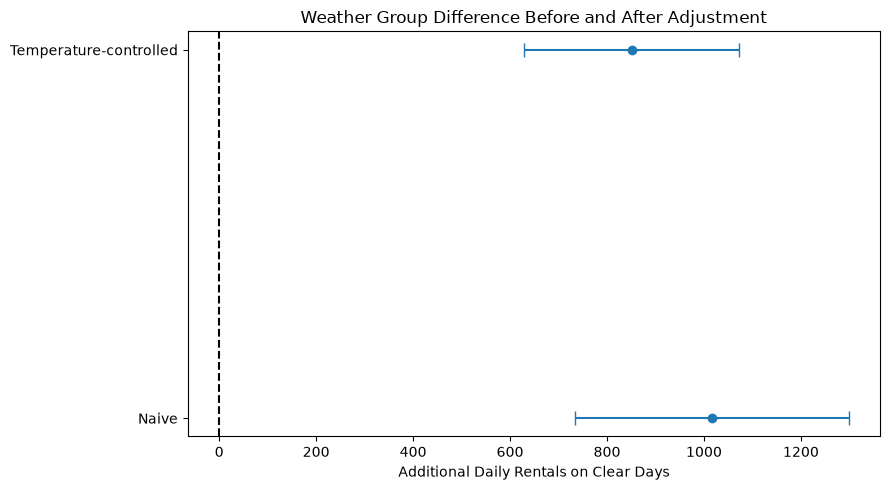

In [29]:
estimates = [difference, controlled_diff]

lower_errors = [
    difference - ci_lower,
    controlled_diff - bootstrap_lower
]

upper_errors = [
    ci_upper - difference,
    bootstrap_upper - controlled_diff
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    estimates,
    ["Naive", "Temperature-controlled"],
    xerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Additional Daily Rentals on Clear Days")
plt.title("Weather Group Difference Before and After Adjustment")

plt.tight_layout()
plt.show()

In [30]:
year_table = pd.crosstab(
    df["yr"],
    df["weather_group"],
    normalize="columns"
) * 100

print(year_table.round(1))

weather_group  Clear  Non-Clear
yr                             
0               48.8       51.9
1               51.2       48.1


In [31]:
year_table = pd.crosstab(
    df["yr"],
    df["weather_group"],
    normalize="columns"
) * 100

print(year_table.round(1))

weather_group  Clear  Non-Clear
yr                             
0               48.8       51.9
1               51.2       48.1


In [32]:
yearly_demand = df.groupby("yr")["cnt"].mean()

print(yearly_demand.round(2))

yr
0    3405.76
1    5599.93
Name: cnt, dtype: float64


In [33]:
df["temp_3"] = pd.qcut(
    df["temp"],
    q=3,
    labels=["Low", "Medium", "High"]
)

estimate_3 = adjusted_difference(df, "temp_3")

print("Three-band estimate:", round(estimate_3, 2))

Three-band estimate: 821.12


In [34]:
df["temp_5"] = pd.qcut(
    df["temp"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

estimate_5 = adjusted_difference(df, "temp_5")

print("Five-band estimate:", round(estimate_5, 2))

Five-band estimate: 783.33


In [35]:
df["temp_fixed"] = pd.cut(
    df["temp"],
    bins=4,
    labels=["B1", "B2", "B3", "B4"]
)

estimate_fixed = adjusted_difference(df, "temp_fixed")

print("Fixed-width estimate:", round(estimate_fixed, 2))

Fixed-width estimate: 757.87


In [36]:
sensitivity = pd.DataFrame({
    "Method": [
        "Naive",
        "4 temperature bands",
        "3 temperature bands",
        "5 temperature bands",
        "Fixed-width bands"
    ],
    "Difference": [
        difference,
        controlled_diff,
        estimate_3,
        estimate_5,
        estimate_fixed
    ]
})

sensitivity["Change vs Main"] = (
    sensitivity["Difference"] - controlled_diff
)

print(sensitivity.round(2))

                Method  Difference  Change vs Main
0                Naive     1015.86          163.94
1  4 temperature bands      851.92            0.00
2  3 temperature bands      821.12          -30.80
3  5 temperature bands      783.33          -68.59
4    Fixed-width bands      757.87          -94.06


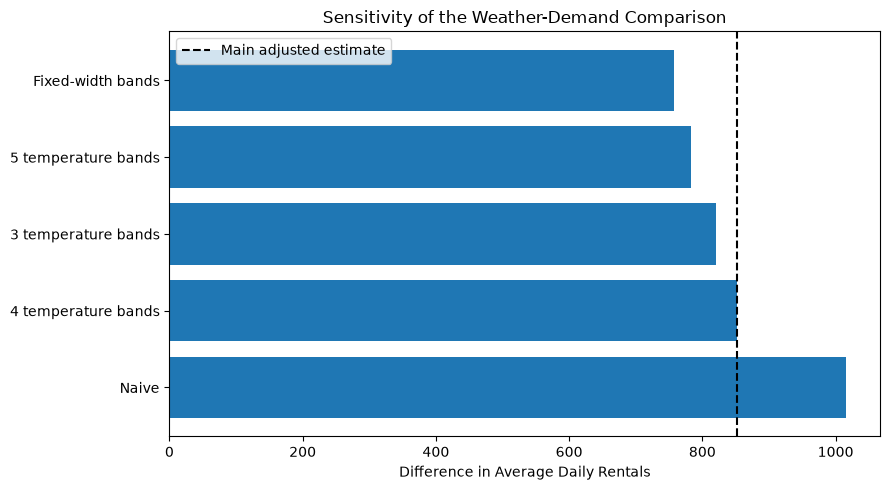

In [37]:
plt.figure(figsize=(9, 5))

plt.barh(
    sensitivity["Method"],
    sensitivity["Difference"]
)

plt.axvline(
    controlled_diff,
    linestyle="--",
    color="black",
    label="Main adjusted estimate"
)

plt.xlabel("Difference in Average Daily Rentals")
plt.title("Sensitivity of the Weather-Demand Comparison")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
df["temp_year"] = (
    df["temp_band"].astype(str)
    + "_"
    + df["yr"].astype(str)
)

print(pd.crosstab(
    df["temp_year"],
    df["weather_group"]
))

weather_group  Clear  Non-Clear
temp_year                      
Q1_0              67         36
Q1_1              48         32
Q2_0              42         42
Q2_1              60         39
Q3_0              44         41
Q3_1              61         36
Q4_0              73         20
Q4_1              68         22


In [39]:
two_conf_estimate = adjusted_difference(
    df,
    "temp_year"
)

print("Naive:", round(difference, 2))

print("Temperature-controlled:",
      round(controlled_diff, 2))

print("Temperature and year controlled:",
      round(two_conf_estimate, 2))

Naive: 1015.86
Temperature-controlled: 851.92
Temperature and year controlled: 779.63


In [40]:
controlled_percent = (
    controlled_diff / non_clear_mean
) * 100

print("Controlled difference in rentals:",
      round(controlled_diff, 2))

print("Controlled percentage difference:",
      round(controlled_percent, 2), "%")

print("Proposed decision threshold: 10%")

Controlled difference in rentals: 851.92
Controlled percentage difference: 22.07 %
Proposed decision threshold: 10%


In [41]:
threshold_rentals = non_clear_mean * 0.10

print("Decision threshold in rentals:",
      round(threshold_rentals, 2))

print("Adjusted estimate:",
      round(controlled_diff, 2))

print("Adjusted interval:",
      round(bootstrap_lower, 2),
      "to",
      round(bootstrap_upper, 2))

Decision threshold in rentals: 386.09
Adjusted estimate: 851.92
Adjusted interval: 628.66 to 1072.28


In [42]:
if bootstrap_lower > threshold_rentals:
    print("Evidence supports an association above the 10% threshold.")

elif controlled_diff > threshold_rentals:
    print("The estimate exceeds 10%, but uncertainty remains.")

else:
    print("The controlled estimate does not reach the 10% threshold.")

Evidence supports an association above the 10% threshold.


In [43]:
rng = np.random.default_rng(42)

two_conf_bootstrap = []

groups = list(
    df.groupby(
        ["temp_year", "weather_group"]
    )
)

for i in range(2000):

    samples = []

    for name, group in groups:

        positions = rng.choice(
            len(group),
            size=len(group),
            replace=True
        )

        samples.append(group.iloc[positions])

    sample_df = pd.concat(samples)

    estimate = adjusted_difference(
        sample_df,
        "temp_year"
    )

    two_conf_bootstrap.append(estimate)

lower = np.percentile(two_conf_bootstrap, 2.5)
upper = np.percentile(two_conf_bootstrap, 97.5)

print("Two-confounder estimate:",
      round(two_conf_estimate, 2))

print("Bootstrap 95% CI:",
      round(lower, 2), "to", round(upper, 2))

Two-confounder estimate: 779.63
Bootstrap 95% CI: 630.36 to 932.61
